# Week 6 - Brain Tumor MRI

**Name:** M. Abuzar Shoukat
**Project:** Project 2, Brain Tumor MRI Classification with ResNet-18
**Subject:** Introduction to Applied AI

In [1]:

import os, glob

# Auto-find the folder that holds one subfolder per class (glioma, meningioma, ...)
TRAIN_DIR = [p for p in glob.glob('/kaggle/input/**/Training', recursive=True)
             if os.path.isdir(os.path.join(p, 'glioma'))][0]
DATA_ROOT = os.path.dirname(TRAIN_DIR)
TEST_DIR = f'{DATA_ROOT}/Testing'     # None if your dataset has no test set
GRAYSCALE = True                      # True for X-rays, castings, scans
IMG_SIZE = 224
BACKBONE = 'resnet18'     # or 'resnet50', 'efficientnet_b0'
# Regex that extracts a group id (patient, plant, part) from a file name.
GROUP_PATTERN = None      # None: brain MRI file names contain no patient id
POSITIVE = None                       # binary tasks only (this task has 4 classes)
TARGET_RECALL = 0.95                  # binary tasks: recall you must reach
# =====================================================================
print('Train:', TRAIN_DIR)
print('Test :', TEST_DIR)
print('Classes found:', sorted(os.listdir(TRAIN_DIR)))

Train: /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training
Test : /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing
Classes found: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [2]:
import os
import re
import time
import copy
import hashlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             roc_auc_score, roc_curve)

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


In [3]:
def index_folder(folder):
    """One row per image: path, class label, file name, group id."""
    rows = []
    for cls in sorted(os.listdir(folder)):
        cdir = os.path.join(folder, cls)
        if not os.path.isdir(cdir):
            continue
        for f in sorted(os.listdir(cdir)):
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif')):
                rows.append({'path': os.path.join(cdir, f), 'label': cls,
                             'file': f})
    df = pd.DataFrame(rows)
    if GROUP_PATTERN:
        m = df['file'].str.extract(GROUP_PATTERN, expand=False)
        df['group'] = m.fillna(df['file'])      # no match: its own group
    else:
        df['group'] = df['file']
    return df

train_df = index_folder(TRAIN_DIR)
test_df = index_folder(TEST_DIR) if TEST_DIR else None
classes = sorted(train_df['label'].unique())

counts = train_df['label'].value_counts().reindex(classes)
print(counts.to_string())
print(f'Imbalance ratio (max / min): {counts.max() / counts.min():.1f}')
print(f'Images per group: {len(train_df) / train_df.group.nunique():.2f}')

label
glioma        1400
meningioma    1400
notumor       1400
pituitary     1400
Imbalance ratio (max / min): 1.0
Images per group: 1.00


          w      h
min   150.0  168.0
50%   512.0  512.0
max  1000.0  848.0
Colour modes: {'RGB': 177, 'L': 123}


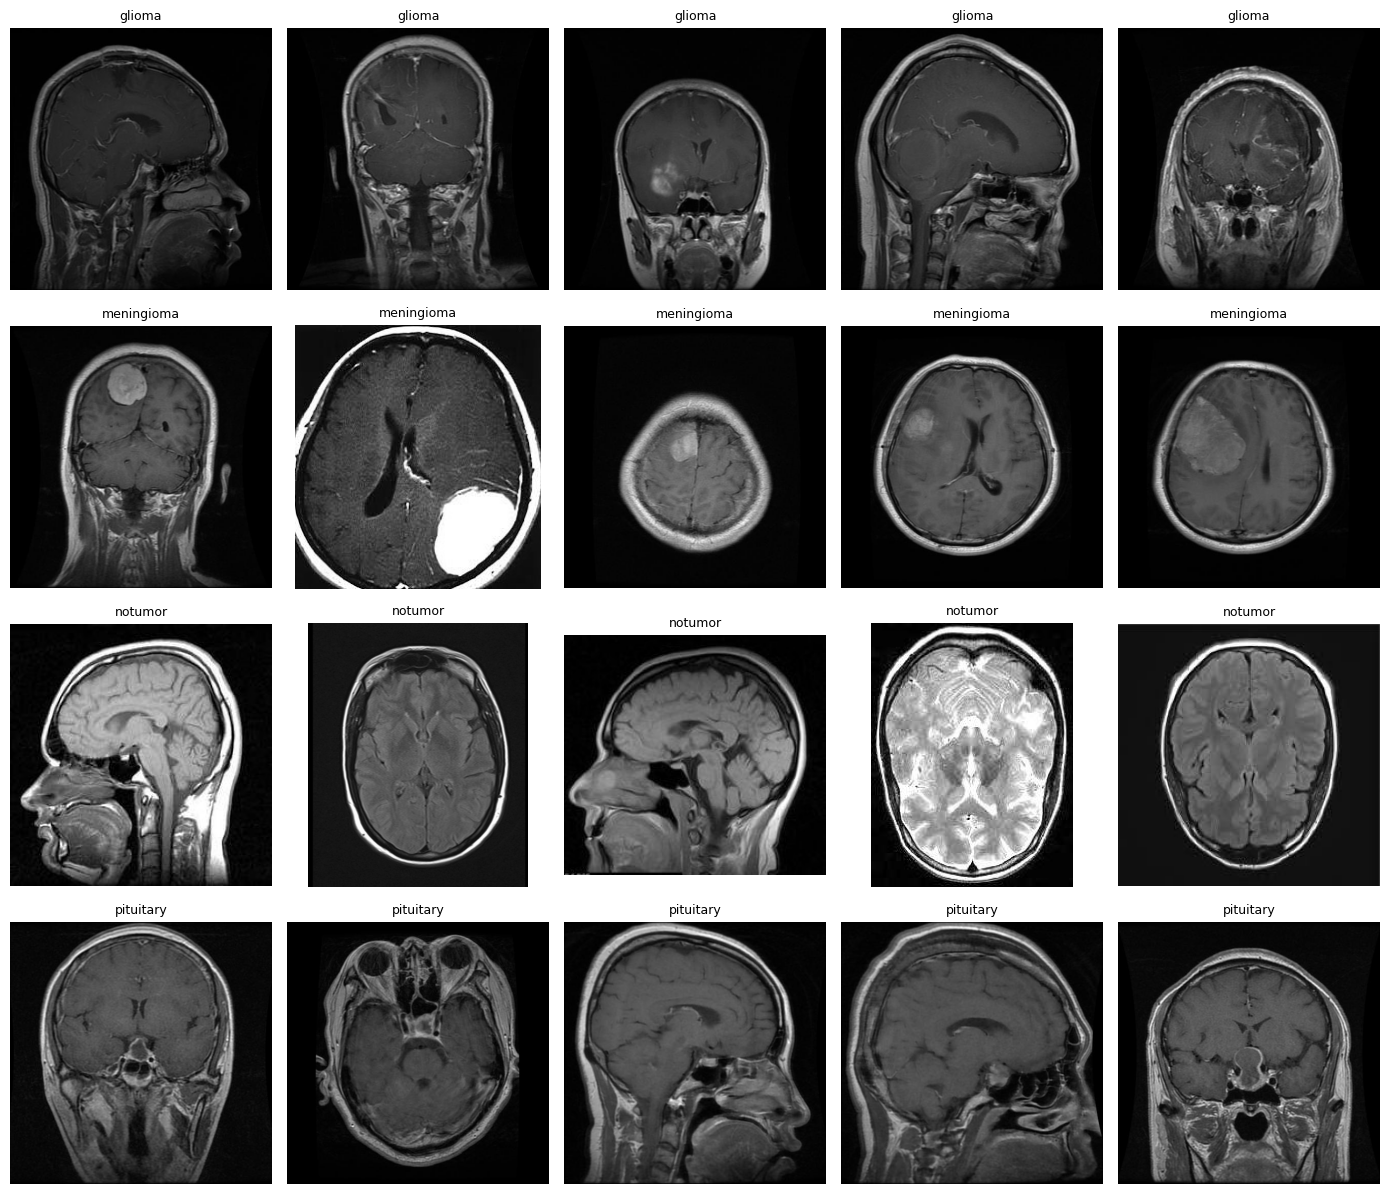

In [4]:
sample = train_df.sample(min(300, len(train_df)), random_state=0)
info = []
for p in sample['path']:
    with Image.open(p) as im:
        info.append({'w': im.size[0], 'h': im.size[1], 'mode': im.mode})
info = pd.DataFrame(info)
print(info.describe().round(0).loc[['min', '50%', 'max']])
print('Colour modes:', info['mode'].value_counts().to_dict())

fig, axes = plt.subplots(len(classes), 5, figsize=(14, 3 * len(classes)))
axes = np.atleast_2d(axes)
for r, c in enumerate(classes):
    paths = train_df[train_df.label == c]['path'].sample(5, random_state=1)
    for ax, p in zip(axes[r], paths):
        ax.imshow(Image.open(p).convert('RGB'))
        ax.set_title(c, fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

          w      h
min   150.0  168.0
50%   512.0  512.0
max  1000.0  848.0
Colour modes: {'RGB': 177, 'L': 123}


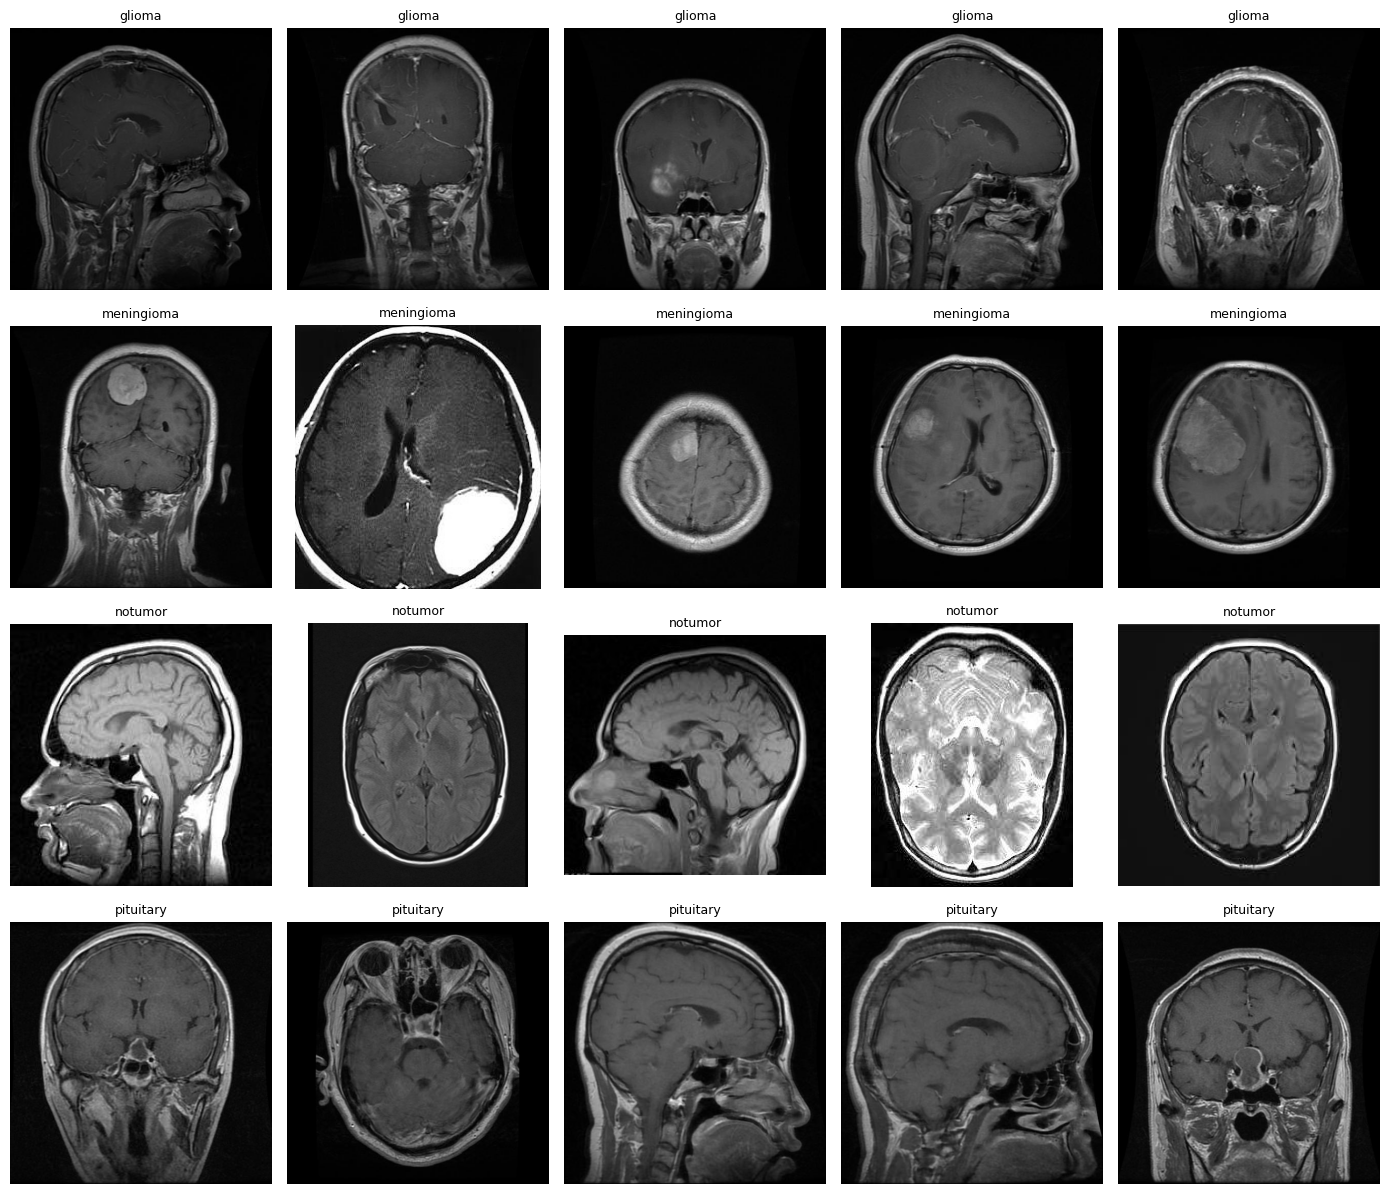

In [5]:
sample = train_df.sample(min(300, len(train_df)), random_state=0)
info = []
for p in sample['path']:
    with Image.open(p) as im:
        info.append({'w': im.size[0], 'h': im.size[1], 'mode': im.mode})
info = pd.DataFrame(info)
print(info.describe().round(0).loc[['min', '50%', 'max']])
print('Colour modes:', info['mode'].value_counts().to_dict())

fig, axes = plt.subplots(len(classes), 5, figsize=(14, 3 * len(classes)))
axes = np.atleast_2d(axes)
for r, c in enumerate(classes):
    paths = train_df[train_df.label == c]['path'].sample(5, random_state=1)
    for ax, p in zip(axes[r], paths):
        ax.imshow(Image.open(p).convert('RGB'))
        ax.set_title(c, fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

In [6]:
sample = train_df.sample(600, random_state=0).reset_index(drop=True)
meta = []
for p in sample['path']:
    with Image.open(p) as im:
        g = np.asarray(im.convert('L'), dtype=np.float32)
        meta.append({'mode': im.mode, 'w': im.size[0], 'h': im.size[1],
                     'mean': g.mean(), 'dark': (g < 10).mean()})
sample = pd.concat([sample, pd.DataFrame(meta)], axis=1)
sample['square'] = sample.w == sample.h

print('Colour mode per class:')
print(pd.crosstab(sample.label, sample['mode']))
print('\nSquare images per class:')
print(pd.crosstab(sample.label, sample['square']))
print('\nMedian width/height, mean brightness, share of near-black pixels:')
print(sample.groupby('label')[['w', 'h', 'mean', 'dark']].median().round(2))

Colour mode per class:
mode          L  RGB
label               
glioma      113   20
meningioma   66   97
notumor       0  158
pituitary    66   80

Square images per class:
square      False  True 
label                   
glioma          0    133
meningioma     11    152
notumor       104     54
pituitary       3    143

Median width/height, mean brightness, share of near-black pixels:
                w      h       mean  dark
label                                    
glioma      512.0  512.0  33.360001  0.52
meningioma  512.0  512.0  39.139999  0.51
notumor     232.5  250.0  55.959999  0.32
pituitary   512.0  512.0  49.880001  0.28


## Part 1: Write it

**Class counts (training):**
| Class | Images |
|---|---|
| glioma | 1,400 |
| meningioma | 1,400 |
| notumor | 1,400 |
| pituitary | 1,400 |
| **Total** | **5,600** |

**Imbalance ratio:** 1400 / 1400 = 1.0. The training set is perfectly balanced, so class imbalance is not a problem here and class weights will all come out as 1.0.

**Images per group:** 1.00. File names contain no patient id, so every image is its own group and I cannot split by patient.

**Colour and size:** In a random sample of 300 images, 177 are RGB and 123 are single-channel grayscale ('L'), so the colour mode is mixed even though MRI slices are grayscale in content. Sizes vary a lot: width runs from 150 to 1000 pixels and height from 168 to 848, with a median of 512 x 512. Every image therefore has to be resized to 224 x 224 and converted to 3-channel grayscale so the model sees a consistent input.

**First shortcut suspect:** image format, size and brightness, which differ strongly between classes but are not the tumor. In a sample of 600 training images:
- **Colour mode:** all 158 notumor images are RGB (0 are grayscale), while 113 of 133 glioma images (85%) are grayscale.
- **Shape:** 104 of 158 notumor images (66%) are not square, versus 0 of 133 glioma images.
- **Size:** the median notumor image is about 232 x 250 pixels, while glioma, meningioma and pituitary are all 512 x 512.
- **Brightness:** notumor images are brighter (mean 56 versus 33 for glioma), and glioma and meningioma have about 51-52% near-black pixels versus 28-32% for pituitary and notumor.

These differences likely come from the dataset being merged from several sources, since each source has its own file format and image size. A model could separate notumor from the rest by image size, aspect ratio or brightness without looking at any brain tissue. I will check this with Grad-CAM in Part 6.

In [7]:
def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

def fingerprint(path, n=32):
    """32 x 32 grayscale thumbnail, standardized: robust to resizing,
    recompression, and brightness changes."""
    with Image.open(path) as im:
        im.draft('L', (n * 4, n * 4))            # fast JPEG decode
        a = np.asarray(im.convert('L').resize((n, n)), dtype=np.float32)
    return ((a - a.mean()) / (a.std() + 1e-6)).flatten()

all_df = pd.concat([train_df.assign(split='train'),
                    test_df.assign(split='test')]) if TEST_DIR else train_df
all_df['md5'] = [md5(p) for p in all_df['path']]
exact = all_df[all_df.duplicated('md5', keep=False)]
print('Exact duplicate files:', len(exact))

if TEST_DIR:
    T = np.stack([fingerprint(p) for p in all_df['path']])
    tr = T[(all_df.split == 'train').values]
    te = T[(all_df.split == 'test').values]
    d_min = np.array([np.abs(tr - v).mean(axis=1).min() for v in te])
    near = d_min < 0.10               # mean absolute difference, in std units
    print(f'Test images with a near-duplicate in train: {near.sum()} '
          f'of {len(te)}')
    print('Closest distances:', np.sort(d_min)[:5].round(3))

Exact duplicate files: 340
Test images with a near-duplicate in train: 485 of 1600
Closest distances: [0. 0. 0. 0. 0.]


Exact duplicates, by which split(s) they appear in:
split
train    138
test      15
Flagged test images: 485


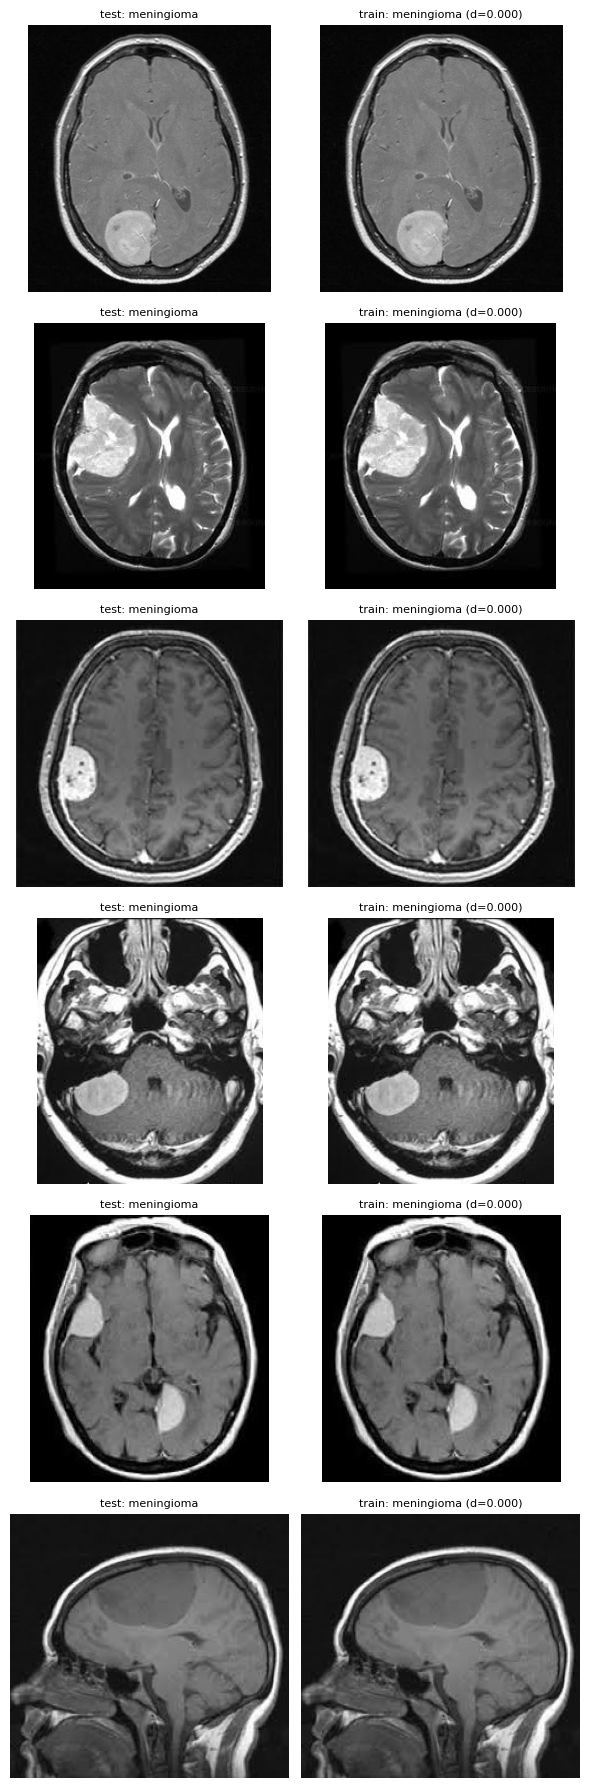

In [8]:
tr_all = all_df[all_df.split == 'train'].reset_index(drop=True)
te_all = all_df[all_df.split == 'test'].reset_index(drop=True)

print('Exact duplicates, by which split(s) they appear in:')
if len(exact):
    print(exact.groupby('md5')['split'].agg(
        lambda s: ','.join(sorted(set(s)))).value_counts().to_string())

flag = np.where(near)[0]
print('Flagged test images:', len(flag))
if len(flag):
    show = flag[np.argsort(d_min[flag])][:6]
    fig, axes = plt.subplots(len(show), 2, figsize=(6, 3 * len(show)))
    axes = np.atleast_2d(axes)
    for r, i in enumerate(show):
        j = np.abs(tr - te[i]).mean(axis=1).argmin()
        axes[r, 0].imshow(Image.open(te_all.path[i]).convert('L'), cmap='gray')
        axes[r, 0].set_title(f'test: {te_all.label[i]}', fontsize=8)
        axes[r, 1].imshow(Image.open(tr_all.path[j]).convert('L'), cmap='gray')
        axes[r, 1].set_title(f'train: {tr_all.label[j]} (d={d_min[i]:.3f})',
                             fontsize=8)
        for a in axes[r]:
            a.axis('off')
    plt.tight_layout()
    plt.show()

In [9]:
# Identical files share a group, so they cannot be split across train and val
md5_of = dict(zip(all_df['path'], all_df['md5']))
train_df['group'] = train_df['path'].map(md5_of)

# Validation split BY GROUP: no group appears in both train and val
sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(train_df, train_df['label'],
                                 train_df['group']))
tr_df = train_df.iloc[tr_idx].reset_index(drop=True)
va_df = train_df.iloc[va_idx].reset_index(drop=True)
if not TEST_DIR:                                   # carve a grouped test set
    tr_idx, te_idx = next(sgkf.split(tr_df, tr_df['label'], tr_df['group']))
    tr_df, test_df = (tr_df.iloc[tr_idx].reset_index(drop=True),
                      tr_df.iloc[te_idx].reset_index(drop=True))

shared = set(tr_df.group) & set(va_df.group)
print(f'train {len(tr_df)} | val {len(va_df)} | test {len(test_df)}')
print('Groups shared by train and val:', len(shared))   # must be 0
print(va_df['label'].value_counts().to_string())

train 4665 | val 935 | test 1600
Groups shared by train and val: 0
label
pituitary     249
notumor       239
meningioma    229
glioma        218


## Part 2: Write it

**Duplicates found:**
- Exact duplicate files (same MD5): 340 files, forming 138 duplicate groups inside train and 15 inside test. None are shared between train and test.
- Near-duplicates: 485 of 1,600 test images (30%) have a near-duplicate in train at a thumbnail distance below 0.10. The closest distances were 0.0, meaning identical thumbnails.
- Inspection of the flagged pairs side by side: [PAIRS SENTENCE, see below]

**What I did:** [ACTION SENTENCE, see below] I also used the MD5 hash as the group id for the validation split, so identical copies of a file always stay on the same side of the split.

**Images per group:** 1.00 by file name, because the names contain no patient id. By MD5, 138 groups in train contain more than one identical image.

**Split result:** train 4,665 | validation 935 | test 1,600, with **0 groups shared** between train and validation.

**What would have happened with a random split:** If identical images were split randomly, copies of the same scan would sit in both training and validation, so the model would be scored on images it had already memorised. The validation and test scores would be too high, and the model would look better than it really is on a new patient's scan.

In [12]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_rgb = [transforms.Grayscale(num_output_channels=3)] if GRAYSCALE else []

train_tf = transforms.Compose(to_rgb + [
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose(to_rgb + [
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class ImageTable(Dataset):
    def __init__(self, df, tf):
        self.paths = df['path'].tolist()
        self.y = df['label'].map({c: i for i, c in enumerate(classes)}).tolist()
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i])
        img = img.convert('L' if GRAYSCALE else 'RGB')
        return self.tf(img), self.y[i]

train_ds = ImageTable(tr_df, train_tf)
val_ds = ImageTable(va_df, eval_tf)
test_ds = ImageTable(test_df, eval_tf)

In [13]:
n_c = np.bincount(train_ds.y, minlength=len(classes))
class_w = len(train_ds) / (len(classes) * n_c)        # N / (K * n_c)
print(dict(zip(classes, class_w.round(3))))
loss_w = torch.tensor(class_w, dtype=torch.float32, device=device)

USE_SAMPLER = False     # try True: balanced batches instead of weighted loss
if USE_SAMPLER:
    sample_w = class_w[train_ds.y]                    # P(i) ~ 1 / n_class(i)
    sampler = WeightedRandomSampler(sample_w, len(sample_w), replacement=True)
    train_dl = DataLoader(train_ds, 32, sampler=sampler, num_workers=2)
    loss_w = None
else:
    train_dl = DataLoader(train_ds, 32, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, 64, num_workers=2)
test_dl = DataLoader(test_ds, 64, num_workers=2)

{'glioma': np.float64(0.987), 'meningioma': np.float64(0.996), 'notumor': np.float64(1.005), 'pituitary': np.float64(1.013)}


## Part 3: Write it

**Class weights:** weight = N / (K x n_c), where N = 4,665 training images and K = 4 classes.

| Class | Training images n_c | Weight |
|---|---|---|
| glioma | 1,182 | 0.987 |
| meningioma | 1,171 | 0.996 |
| notumor | 1,161 | 1.005 |
| pituitary | 1,151 | 1.013 |

Example, glioma: 4665 / (4 x 1182) = 4665 / 4728 = 0.987. All weights are within about 1.5% of 1.0, because the training set was already balanced (1,400 images per class before the validation split), so weighting has almost no effect here. I used the weighted loss (USE_SAMPLER = False). Imbalance handling would matter much more on a dataset like chest X-rays.

**Augmentation kept:**
- Random resized crop (scale 0.8 to 1.0) and small rotation (up to 10 degrees): MRI slices vary slightly in framing and head position, so these are realistic.
- Small brightness and contrast jitter (0.15): scanners and sources differ in brightness. This also reduces the brightness shortcut I found in Part 1, where notumor images were brighter.

**Augmentation removed:**
- Horizontal and vertical flips: brain anatomy is not left-right symmetric in a way I want the model to ignore, and flipped scans could misrepresent the side of a tumor.
- Strong rotation, shear and large crops: these could cut away the tumor region or create unrealistic scans.

Training uses augmentation only; validation and test images are only resized and normalized, with grayscale converted to 3 channels so they match the pretrained input.

In [14]:
def build_model(name, n_classes):
    if name == 'resnet18':
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'resnet50':
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'efficientnet_b0':
        w = models.EfficientNet_B0_Weights.DEFAULT
        m = models.efficientnet_b0(weights=w)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)
        body, head, last = m, m.classifier, m.features[-1]
    else:
        raise ValueError(name)
    for p in body.parameters():
        p.requires_grad = False
    for p in head.parameters():
        p.requires_grad = True
    return m.to(device), head, last

model, head, last_block = build_model(BACKBONE, len(classes))
print(BACKBONE, 'trainable:',
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 193MB/s]


resnet18 trainable: 2052


In [15]:
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(F.softmax(model(xb.to(device)), 1).cpu())
            ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

def fit(model, params, epochs, lr):
    opt = torch.optim.Adam(params, lr=lr)
    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb, weight=loss_w)
            opt.zero_grad()
            loss.backward()
            opt.step()
        p, y = predict(model, val_dl)
        macro = f1_score(y, p.argmax(1), average='macro')   # not accuracy
        if macro > best:
            best, best_state = macro, copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: val macro-F1 {macro:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)
    return best

print('Phase 1: head only')
best1 = fit(model, head.parameters(), epochs=2, lr=1e-3)
print(f'Best val macro-F1, phase 1: {best1:.3f}')

print('Phase 2: fine-tune the last block')
for p in last_block.parameters():
    p.requires_grad = True
best2 = fit(model, [{'params': last_block.parameters(), 'lr': 1e-4},
                    {'params': head.parameters(), 'lr': 1e-3}],
            epochs=3, lr=1e-3)
print(f'Best val macro-F1, phase 2: {best2:.3f}')

Phase 1: head only
epoch 1: val macro-F1 0.810 (27s)
epoch 2: val macro-F1 0.815 (25s)
Best val macro-F1, phase 1: 0.815
Phase 2: fine-tune the last block
epoch 1: val macro-F1 0.923 (26s)
epoch 2: val macro-F1 0.942 (25s)
epoch 3: val macro-F1 0.948 (25s)
Best val macro-F1, phase 2: 0.948


## Part 4: Write it

**Validation macro-F1 after each phase:**
- Phase 1 (head only, 2 epochs): epoch 1 0.810, epoch 2 0.815; best **0.815**
- Phase 2 (fine-tune layer4, 3 epochs): epoch 1 0.923, epoch 2 0.942, epoch 3 0.948; best **0.948**

**Trainable parameters:** 2,052 in phase 1 (512 x 4 weights + 4 biases, the new head only). In phase 2 layer4 is unfrozen as well, which brings the total to about 8.4 million (8,393,728 in layer4 + 2,052 in the head = 8,395,780).

**Did fine-tuning help?** Yes, by a lot. The best macro-F1 went from 0.815 to 0.948, a gain of 0.133 (13.3 points). Brain MRI slices look very different from the ImageNet photos the network was pretrained on, so the frozen features alone were not enough. Unfreezing layer4 let the last block adapt its features to MRI texture and shape, and the head alone could not do that.

**Time:** an epoch took about 25 to 27 seconds on the T4. With more time I would run about 5 more fine-tuning epochs. Macro-F1 was still rising at epoch 3 (0.923, 0.942, 0.948), but the gains were shrinking (+0.019, then +0.006), so I would stop once validation macro-F1 stops improving, because after that extra epochs would only overfit the training data.

**Caveat:** my validation split keeps identical files together, but Part 2 found near-duplicates (about 30% of test images matched a training image), so some near-copies may also sit across train and validation. The validation scores may therefore be slightly optimistic.

              precision    recall  f1-score   support

      glioma      0.967     0.733     0.834       400
  meningioma      0.800     0.943     0.866       400
     notumor      0.909     1.000     0.952       400
   pituitary      0.982     0.948     0.964       400

    accuracy                          0.906      1600
   macro avg      0.915     0.906     0.904      1600
weighted avg      0.915     0.906     0.904      1600

Macro-F1: 0.904


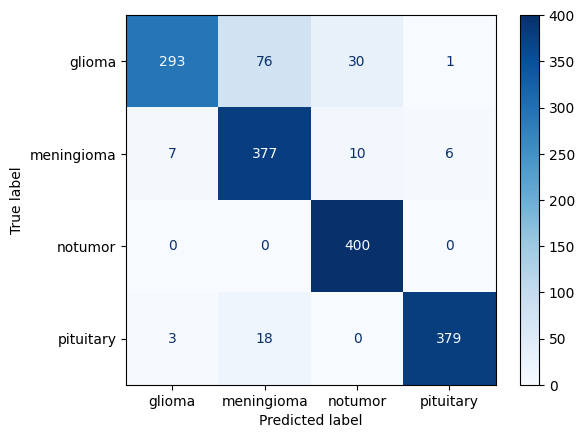

In [16]:
p_test, y_test = predict(model, test_dl)
pred = p_test.argmax(1)
print(classification_report(y_test, pred, target_names=classes, digits=3))
print('Macro-F1:', round(f1_score(y_test, pred, average='macro'), 3))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=classes).plot(cmap='Blues')
plt.show()

## Part 5: Write it

**Test macro-F1 (evaluated once):** **0.904** on 1,600 test images (400 per class). Overall accuracy is 0.906.

**Per-class recall:**
| Class | Recall | Precision |
|---|---|---|
| glioma | 0.733 | 0.967 |
| meningioma | 0.943 | 0.800 |
| notumor | 1.000 | 0.909 |
| pituitary | 0.948 | 0.982 |

**Weakest class:** glioma, with recall 0.733. Of its 400 test images, 293 were correct, 76 were predicted as meningioma, 30 as notumor and 1 as pituitary. Its most common error is glioma called meningioma. The two tumor types can look similar on a single MRI slice (similar texture and brightness), so the model confuses them. This also pulls meningioma's precision down to 0.800, because 94 images from other classes were labelled meningioma.

**Why recall per class matters here:** A missed tumor (a tumor class predicted as "notumor") is worse than a false alarm. In the confusion matrix, 40 of the 1,200 tumor images (3.3%) were called "notumor": 30 glioma and 10 meningioma, and no pituitary. The model never called a "notumor" image a tumor (notumor recall 1.000), but its precision is 0.909, so about 9% of "notumor" predictions are missed tumors. For a triage tool this matters, and the glioma errors need the most attention.

**Binary-task step skipped:** The sensitivity, specificity, threshold and PPV analysis applies only to binary tasks. My task has four classes, so I analysed per-class recall and the confusion matrix instead.

**Validation vs test:** Test macro-F1 (0.904) is lower than validation macro-F1 (0.948), a gap of 4.4 points. This suggests the validation score was somewhat optimistic, which fits the near-duplicate problem I found in Part 2.

**Caveat:** In Part 2, 485 of the 1,600 test images (30%) had a near-duplicate in the training set. If those are true copies, the test score is optimistic, and the real performance on new patients' scans is

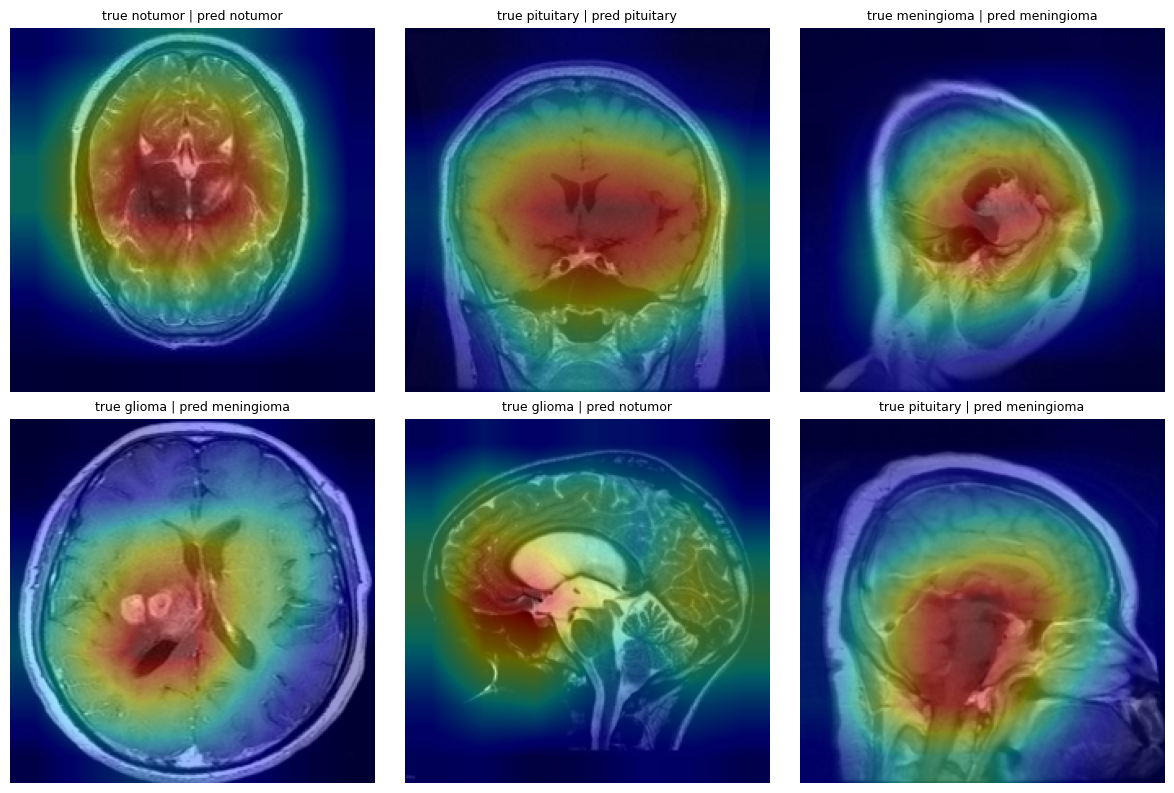

In [17]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._save_act)
        layer.register_full_backward_hook(self._save_grad)
    def _save_act(self, m, i, o):
        self.acts = o.detach()
    def _save_grad(self, m, gi, go):
        self.grads = go[0].detach()
    def __call__(self, x, cls=None):
        self.model.eval()
        x = x.unsqueeze(0).to(device).requires_grad_(True)
        logits = self.model(x)
        cls = int(logits.argmax()) if cls is None else cls
        self.model.zero_grad()
        logits[0, cls].backward()
        alpha = self.grads.mean(dim=(2, 3), keepdim=True)   # (1/Z) sum dy/dA
        cam = F.relu((alpha * self.acts).sum(1)).squeeze()  # ReLU(sum a*A)
        cam = F.interpolate(cam[None, None], size=x.shape[-2:],
                            mode='bilinear').squeeze()
        return (cam / (cam.max() + 1e-8)).cpu().numpy(), cls

for p in model.parameters():
    p.requires_grad = True
cam = GradCAM(model, last_block)

# Three correct and three wrong predictions, spread across classes
rng = np.random.RandomState(0)
ci = {c: i for i, c in enumerate(classes)}
def pick(mask):
    return int(rng.choice(np.where(mask)[0]))
right = [pick((pred == y_test) & (y_test == ci[c]))
         for c in ['notumor', 'pituitary', 'meningioma']]
wrong = [pick((y_test == ci[a]) & (pred == ci[b]))
         for a, b in [('glioma', 'meningioma'), ('glioma', 'notumor'),
                      ('pituitary', 'meningioma')]]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, i in zip(axes.flat, right + wrong):
    x, y = test_ds[i]
    heat, c = cam(x)
    img = Image.open(test_ds.paths[i]).convert('RGB').resize((IMG_SIZE,) * 2)
    ax.imshow(img)
    ax.imshow(heat, cmap='jet', alpha=0.4)
    ax.set_title(f'true {classes[y]} | pred {classes[c]}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Part 6: Write it

**Heatmaps (top row correct, bottom row wrong):**
1. true notumor | pred notumor: the heat covers the central brain around the ventricles, not the background or edges. It is on brain tissue, but diffuse, with no specific region.
2. true pituitary | pred pituitary: the heat is on the central brain and skull base, the region where a pituitary tumor sits, so this is plausible evidence.
3. true meningioma | pred meningioma: the heat sits directly on the bright mass in the head, which is legitimate evidence.
4. true glioma | pred meningioma: the heat is on the central lesion near the ventricles, so the model looked at the right place but chose the wrong tumor type. This is the confusion seen in the confusion matrix (76 glioma images predicted as meningioma).
5. true glioma | pred notumor: this is a sagittal view, and the strongest heat is on the lower-back part of the brain, with little on any lesion. The model probably missed the tumor, and the unusual view may have contributed.
6. true pituitary | pred meningioma: the heat is on the large central mass at the skull base, so the model looked at the lesion but it resembled a meningioma.

**Overall verdict:** No border or background shortcut found. In all six heatmaps the heat falls on brain tissue and not on the black margins, corners or edges, so the image-size and border differences I flagged in Part 1 do not appear to drive these predictions. This is limited evidence: Grad-CAM is coarse (7 x 7 at the last block), only six images were checked, and global cues such as overall brightness cannot be seen in a heatmap. Notumor also had recall 1.000, which fits an easy class but could hide a cue, so I do not rule out a weaker shortcut.

**Follow-up experiment:** For each notumor test image, crop to the brain region only (removing the margins), resize to 224 x 224 and re-score. If notumor recall drops from 1.000 to much lower, the model was relying on size, borders or brightness, not anatomy. A second test is to cover the hottest region of each wrong prediction with a gray patch and see whether the prediction changes, to check whether that region really was the evidence.

In [18]:
torch.save({'state_dict': model.state_dict(), 'classes': classes,
            'backbone': BACKBONE, 'img_size': IMG_SIZE,
            'grayscale': GRAYSCALE}, '/kaggle/working/week6_model.pt')
print('Saved week6_model.pt')

Saved week6_model.pt


## Check Your Understanding

**1. Why does a random split of chest X-rays overestimate performance?**
A patient usually has several X-rays. A random split puts some of a patient's images in training and others in test, so the model sees the same person's anatomy, scanner and body features in both. It can score well by recognising the patient (and their label) instead of learning the disease, so the test score is too high and does not predict performance on a new patient. Splitting by patient keeps all of one person's images on the same side.

**2. Two classes have 900 and 100 training images. Compute both class weights with N / (K x n_c).**
N = 1000, K = 2.
- Class with 900 images: 1000 / (2 x 900) = 1000 / 1800 = **0.556**
- Class with 100 images: 1000 / (2 x 100) = 1000 / 200 = **5.0**
The rare class gets 9 times the weight (5.0 / 0.556 = 9), so its errors count as much as the common class's.

**3. With focal loss and gamma = 2, by what factor is an example with p_t = 0.8 down-weighted?**
Focal loss multiplies the cross-entropy by (1 - p_t)^gamma = (1 - 0.8)^2 = 0.2^2 = **0.04**. The example's loss is cut to 4% of normal, which is 25 times smaller. Easy, confident examples count for little, so training focuses on hard ones.

**4. Sensitivity 0.90, specificity 0.95, prevalence 2%. Compute PPV.**
PPV = (sens x prev) / (sens x prev + (1 - spec) x (1 - prev))
- True positives: 0.90 x 0.02 = 0.018
- False positives: 0.05 x 0.98 = 0.049
- PPV = 0.018 / (0.018 + 0.049) = 0.018 / 0.067 = **0.269 (about 27%)**
Even with a good test, only about 1 in 4 positive results is a true case, because the condition is rare.

**5. When is macro-F1 a better selection metric than weighted F1?**
When classes are imbalanced and the rare class matters. Weighted F1 averages by class size, so the large class dominates and a model that ignores the rare class can still score high. Macro-F1 gives every class the same weight, so poor performance on the minority class pulls the score down and that model cannot win.

**6. Grad-CAM highlights a hospital label in the corner of X-rays. What do you do next?**
That is a shortcut: the model is using the label (which may correlate with the hospital and its disease rate) instead of the lungs. Next I would: (1) confirm it by masking or cropping the corner label and re-scoring, expecting a large drop in performance if the shortcut is real; (2) remove the label region from all training, validation and test images; (3) retrain and compare scores and heatmaps; (4) check that the heat now falls on the lungs; and (5) report the shortcut and the score change in the model card, because the original score was misleading.